# Stitching hyperparameters: minimum focal-region size

Initialise the historical grid from retained run-summary/raw-file identities:
Greedy matching,
AC 10 and 20, zero mismatches, minimum focal sizes 1, 25, 50, 100 and 200
inference sites. The minimum applies to connected focal regions after union.
Simulation is on the left and 1KGP on the right. Both diploid
haplotypes are included; each mean gives equal weight to each haplotype.
African means YRI in simulation and AFR in 1KGP; Non-African pools all
remaining populations, using preserved simulation annotations and pedigree labels.

In [1]:
import logging
import pathlib

import IPython.display as ipython_display

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()
logger = logging.getLogger(__name__)

In [2]:
repository_dir = pathlib.Path.cwd()
config_path = {
    "output_dir": repository_dir / "data/ch5/stitching_pt6_min_sizes",
    "method": "greedy",
    "workers": None,
    "dating": {
        "output_subdir": "dated_args",
        "workers": None,
        "helper_threads": 1,
        "post_process": {"split_ultimate": True, "erase_flanks": True},
        "preprocess": {"delete_intervals": [], "split_disjoint": True},
        "estimation": {
            "method": "variational_gamma",
            "time_units": "generations",
            "set_metadata": True,
            "progress": False,
            "singletons_phased": True,
        },
        "compare_full_datasets": ["sim_n300_10mbp_error", "tgp_n300_10mbp"],
        "dataset_linestyles": {"sim_n300_10mbp_error": "-", "tgp_n300_10mbp": "--"},
        "frequency_bins": {
            "cutoffs": [0.01, 0.5],
            "labels": ["DAF < 0.01", "0.01 ≤ DAF < 0.5", "DAF ≥ 0.5"],
        },
    },
    "datasets": [
        {
            "name": "sim_n300_10mbp_error",
            "label": "Simulation",
            "mutation_rate": 2.35e-08,
            "population_metadata": repository_dir
            / "data/ch5/sim_n300_10mbp_error_populations.csv",
            "population_column": "population",
            "african_population": "YRI",
            "analysis_span_bp": [0, 10000000],
        },
        {
            "name": "tgp_n300_10mbp",
            "label": "1KGP",
            "mutation_rate": 1.29e-08,
            "population_metadata": repository_dir
            / "data/general/populations/tgp_3202_pedigree.csv",
            "population_column": "superpopulation",
            "african_population": "AFR",
            "analysis_span_bp": [1000000, 11000000],
        },
    ],
    "baseline_partition_min_focal_region_size": 1,
}
config_path["base_dir"] = repository_dir
config = config_path
experiment = {
    "data_dir": repository_dir.parent / "tsinfer-match-eval/data/stitching_eval",
    "focal_choice": "left",
    "ac_cutoff": [10, 20],
    "min_focal_region_size": [1, 25, 50, 100, 200],
    "max_mismatches": [0],
    "focal_methods": ["greedy"],
    "datasets": [
        {
            "name": "sim_n300_10mbp_error",
            "ts_path": repository_dir.parent
            / "tsinfer-anc-eval/data/match_eval/simulated/OutOfAfrica_3G09-chr20-L0-R1e7-n300-s1-rep0.trees",
        },
        {"name": "tgp_n300_10mbp", "ts_path": None},
    ],
}
config["experiment"] = experiment
config["experiment_base_dir"] = repository_dir.parent / "tsinfer-match-eval"
output_dir = nb_utils.resolve_path(config["output_dir"], repository_dir)
minimum_sizes = sorted(experiment["min_focal_region_size"])
ac_cutoffs = sorted(experiment["ac_cutoff"])
minimum_colors = dict(
    zip(
        minimum_sizes,
        ["#0072B2", "#009E73", "#E69F00", "#CC79A7", "#D55E00"],
        strict=True,
    )
)
cutoff_colors = dict(zip(ac_cutoffs, ["#0072B2", "#D55E00"], strict=True))

## Load and validate the saved runs

Each full path is compared with its stitched path in original reference
parent IDs. Saved focal masks define maximal connected focal regions and
complementary gaps independently of the copying paths. Counts and lengths
are recomputed from these inputs; earlier pt3 summaries are not used.
The independent runs are processed across available CPU cores.

In [3]:
if __name__ == "__main__":
    results = nb_utils.min_sizes_load_results(config_path, workers=config["workers"])
    comparisons = results.comparisons
    lengths = results.lengths
    output_dir.mkdir(parents=True, exist_ok=True)
    comparisons.to_csv(output_dir / "haplotype_results.csv", index=False)
    lengths.to_csv(output_dir / "region_lengths.csv", index=False)
    run_keys = ["dataset", "min_focal_region_size", "ac_cutoff"]
    run_summary = comparisons.groupby(run_keys).agg(
        haplotypes=("sample_id", "size"),
        individuals=("sample_id", "nunique"),
        undefined_switch_increases=(
            "switch_increase_percentage",
            lambda values: values.isna().sum(),
        ),
        empty_focal_regions=("focal_sites", lambda values: values.eq(0).sum()),
        empty_gaps=("gap_sites", lambda values: values.eq(0).sum()),
    )
    run_summary.to_csv(output_dir / "run_summary.csv")
    ipython_display.display(run_summary)

haplotypes  individuals  \
dataset              min_focal_region_size ac_cutoff                            
sim_n300_10mbp_error 1                     10                600          300   
                                           20                600          300   
                     25                    10                600          300   
                                           20                600          300   
                     50                    10                600          300   
                                           20                600          300   
                     100                   10                600          300   
                                           20                600          300   
                     200                   10                600          300   
                                           20                600          300   
tgp_n300_10mbp       1                     10                600          300   
                                           20                600          300   
                     25                    10                600          300   
                                           20                600          300   
                     50                    10                600          300   
                                           20                600          300   
                     100                   10                600          300   
                                           20                600          300   
                     200                   10                600          300   
                                           20                600          300   

                                                      undefined_switch_increases  \
dataset              min_focal_region_size ac_cutoff                               
sim_n300_10mbp_error 1                     10                                  0   
                                           20                                  0   
                     25                    10                                  0   
                                           20                                  0   
                     50                    10                                  0   
                                           20                                  0   
                     100                   10                                  0   
                                           20                                  0   
                     200                   10                                  0   
                                           20                                  0   
tgp_n300_10mbp       1                     10                                  0   
                                           20                                  0   
                     25                    10                                  0   
                                           20                                  0   
                     50                    10                                  0   
                                           20                                  0   
                     100                   10                                  0   
                                           20                                  0   
                     200                   10                                  0   
                                           20                                  0   

                                                      empty_focal_regions  \
dataset              min_focal_region_size ac_cutoff                        
sim_n300_10mbp_error 1                     10                           0   
                                           20                           0   
                     25                    10                           0   
                                     

## Extra switches vs minimum focal size

Extra switches are stitched minus full switches. Percent increases are
calculated per haplotype using full switches as denominator, then averaged.
Zero-switch full paths have undefined increases and are excluded, with counts
reported above. Hourglasses show mean ± one haplotype SEM; these describe
haplotype variability without accounting for within-individual dependence.

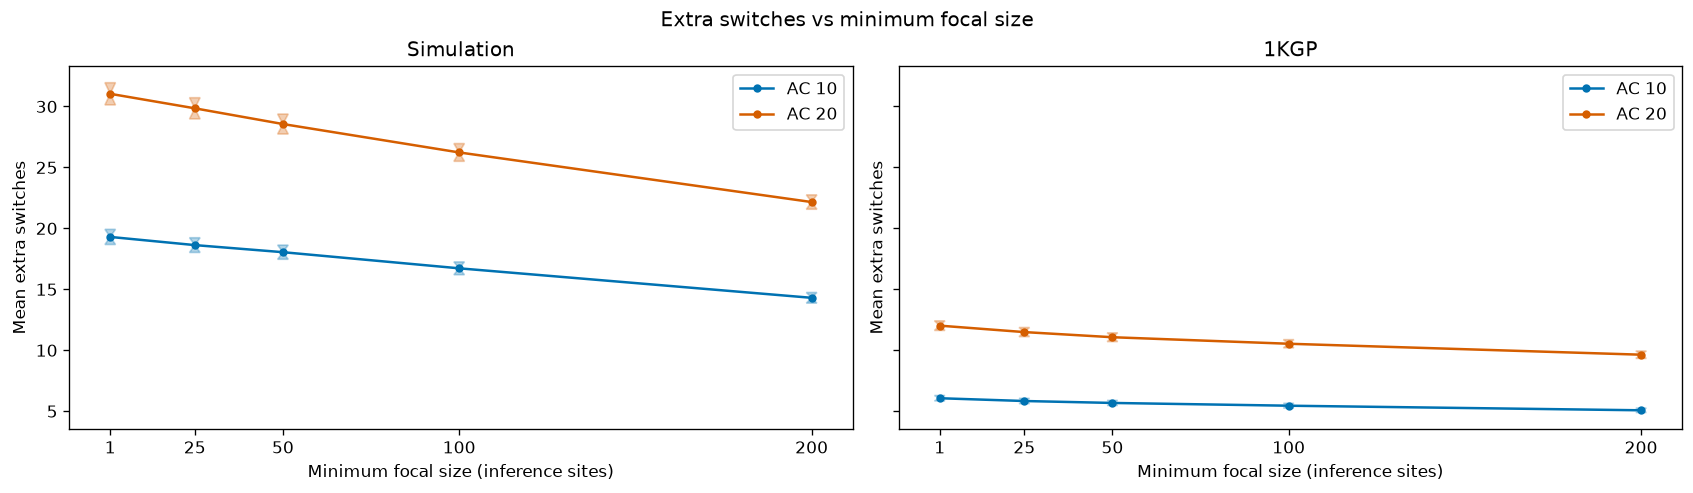

In [5]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_metric(
        "num_extra_switches",
        "Extra switches vs minimum focal size",
        "Mean extra switches",
        curve_values=ac_cutoffs,
        comparisons=comparisons,
        config=config,
        curve_colors=cutoff_colors,
        x_values=minimum_sizes,
        plot_hourglass_alpha=0.3,
        plot_hourglass_width=1.5,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="min_focal_region_size",
        curve_parameter="ac_cutoff",
        x_label="Minimum focal size (inference sites)",
        curve_label="AC {value}",
        x_value_label="Min {value}",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(
        fig, "extra_switches_vs_minimum_focal_size", output_dir=output_dir
    )

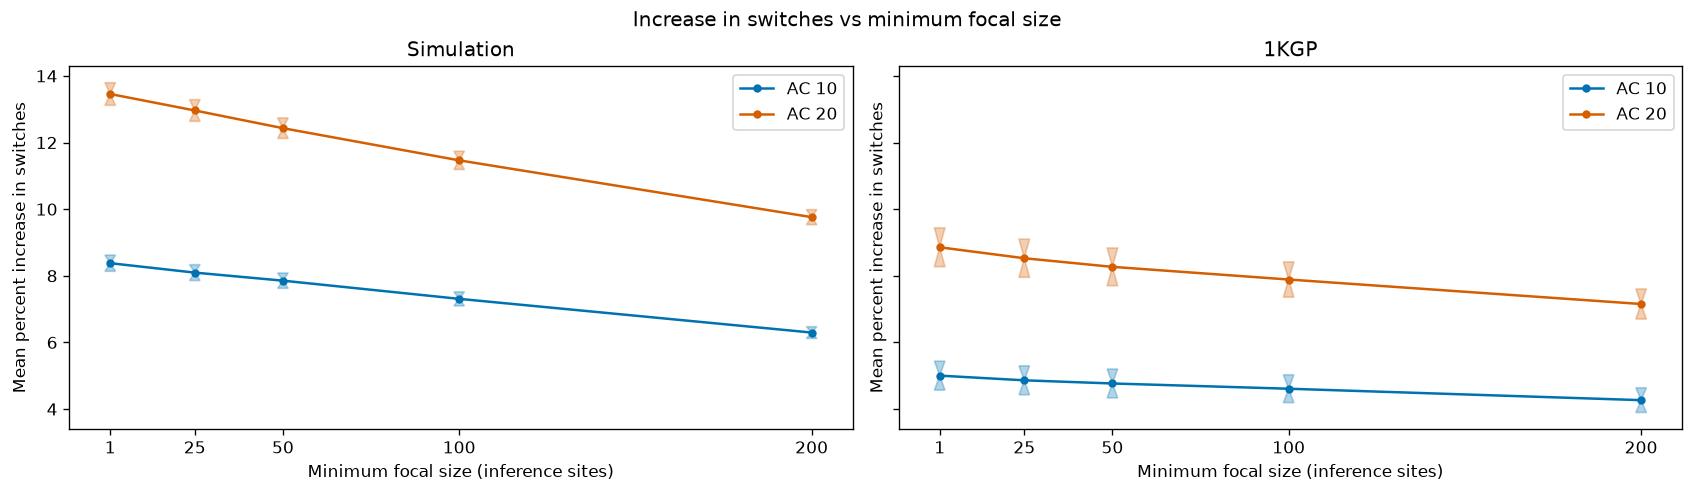

In [6]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_metric(
        "switch_increase_percentage",
        "Increase in switches vs minimum focal size",
        "Mean percent increase in switches",
        curve_values=ac_cutoffs,
        comparisons=comparisons,
        config=config,
        curve_colors=cutoff_colors,
        x_values=minimum_sizes,
        plot_hourglass_alpha=0.3,
        plot_hourglass_width=1.5,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="min_focal_region_size",
        curve_parameter="ac_cutoff",
        x_label="Minimum focal size (inference sites)",
        curve_label="AC {value}",
        x_value_label="Min {value}",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(
        fig, "switch_increase_vs_minimum_focal_size", output_dir=output_dir
    )

## Focal region distributions

Coverage uses base pairs within the configured analysis window: 0–10 Mb in
simulation and 1–11 Mb in 1KGP. It uses the saved mask boundaries converted
to physical positions, clipped to these windows, rather than the retained
64 Mb chromosome span. The population curves are haplotype means.
Length distributions pool maximal focal components across all populations.
Histograms show counts; density curves are scaled by interval count and bin
width so that they overlay the same count axis. Rows show AC cutoffs 10 and 20.
The x-axis displays through the pooled 99th percentile for each AC-cutoff row
(configurable); each legend reports the number of intervals beyond the shown
range. KDEs use every interval, and the exported table retains the full tails.

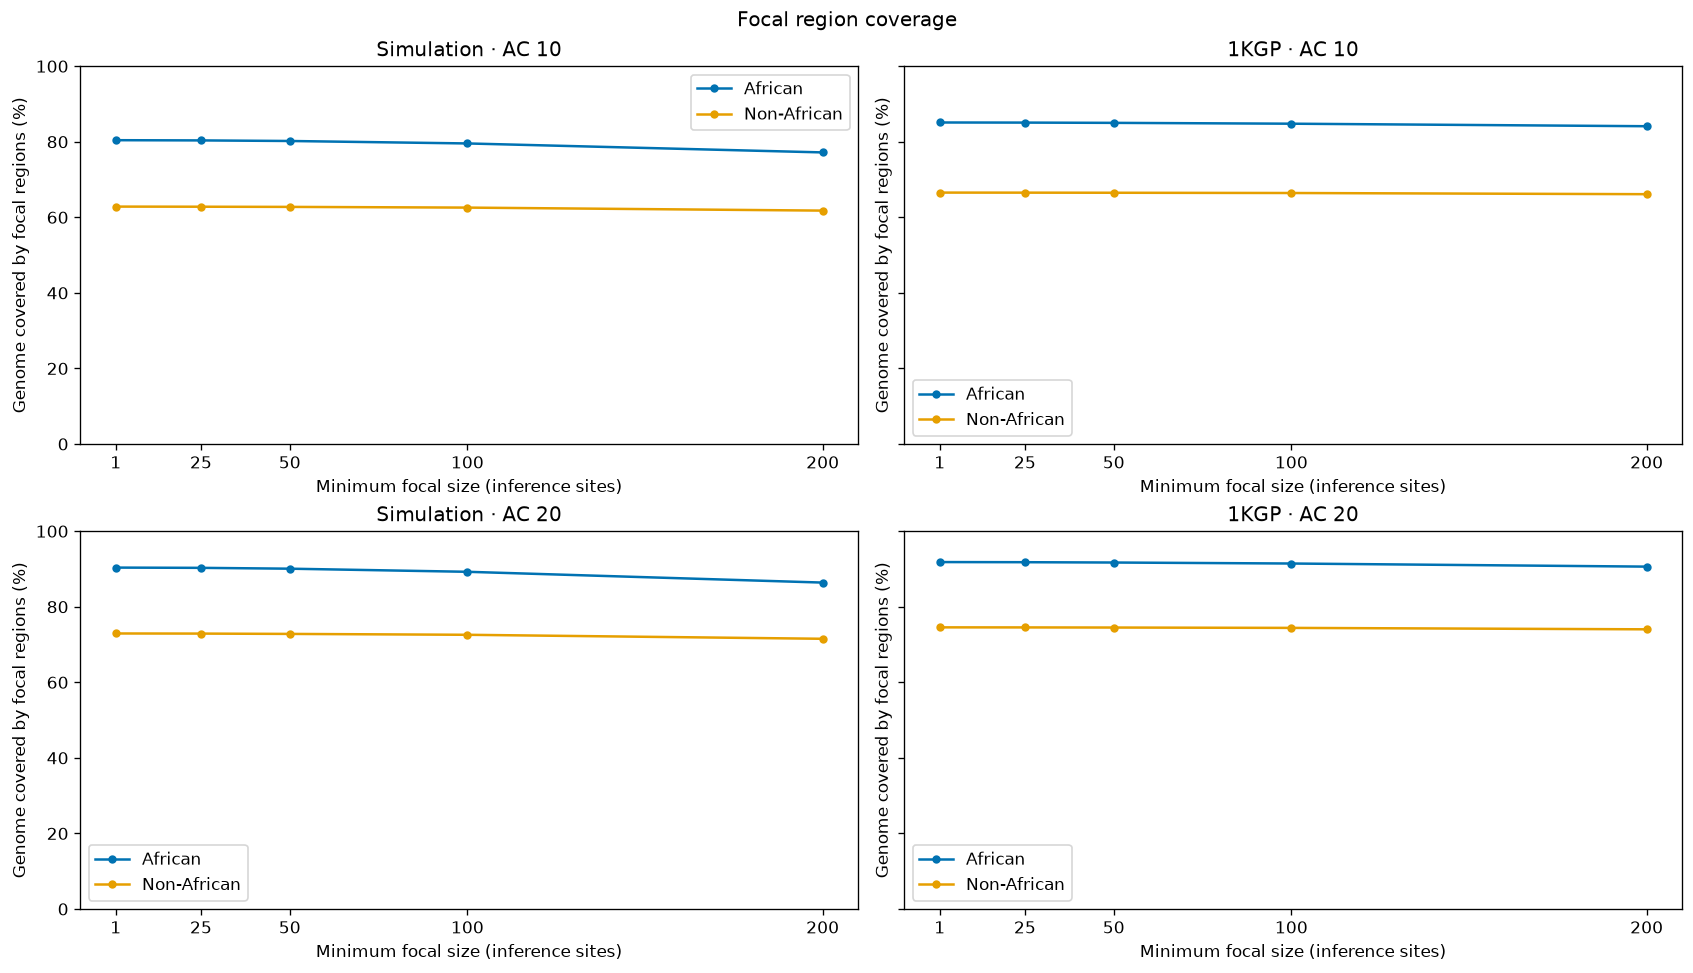

In [7]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_coverage(
        "focal",
        "Focal region coverage",
        curve_values=ac_cutoffs,
        comparisons=comparisons,
        config=config,
        x_values=minimum_sizes,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        plot_population_colors={"African": "#0072B2", "Non-African": "#E69F00"},
        x_parameter="min_focal_region_size",
        curve_parameter="ac_cutoff",
        x_label="Minimum focal size (inference sites)",
        curve_label="AC {value}",
        x_value_label="Min {value}",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(fig, "focal_region_coverage", output_dir=output_dir)

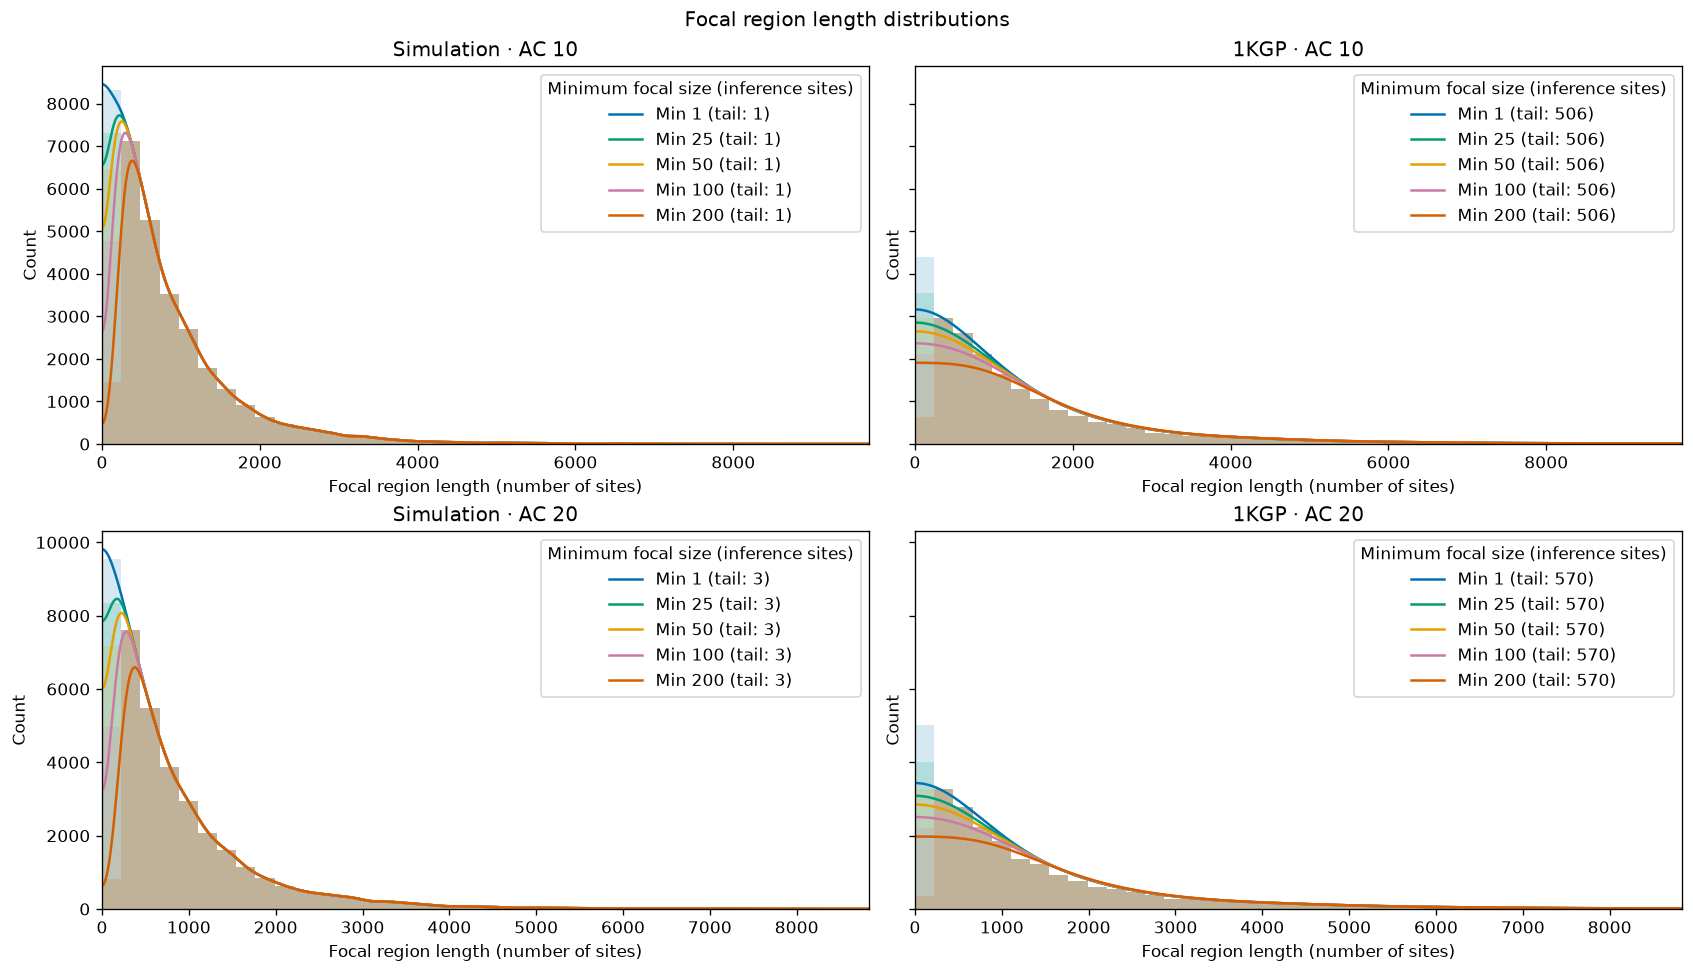

In [8]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_length_distribution(
        "focal",
        "Focal region length distributions",
        curve_values=ac_cutoffs,
        config=config,
        lengths=lengths,
        x_colors=minimum_colors,
        x_values=minimum_sizes,
        plot_histogram_alpha=0.16,
        plot_histogram_bins=40,
        plot_kde_bandwidth="scott",
        plot_kde_grid_size=512,
        plot_length_display_quantile=0.99,
        plot_line_width=1.5,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="min_focal_region_size",
        curve_parameter="ac_cutoff",
        x_label="Minimum focal size (inference sites)",
        curve_label="AC {value}",
        x_value_label="Min {value}",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(fig, "focal_region_length_distributions", output_dir=output_dir)

## Gap distributions

Gaps are maximal complements of focal coverage. Gap coverage is the physical
complement within the same window; lengths count inference sites, including
terminal gaps. Populations, AC-cutoff rows, histograms and density curves follow
the same definitions as the focal region plots.

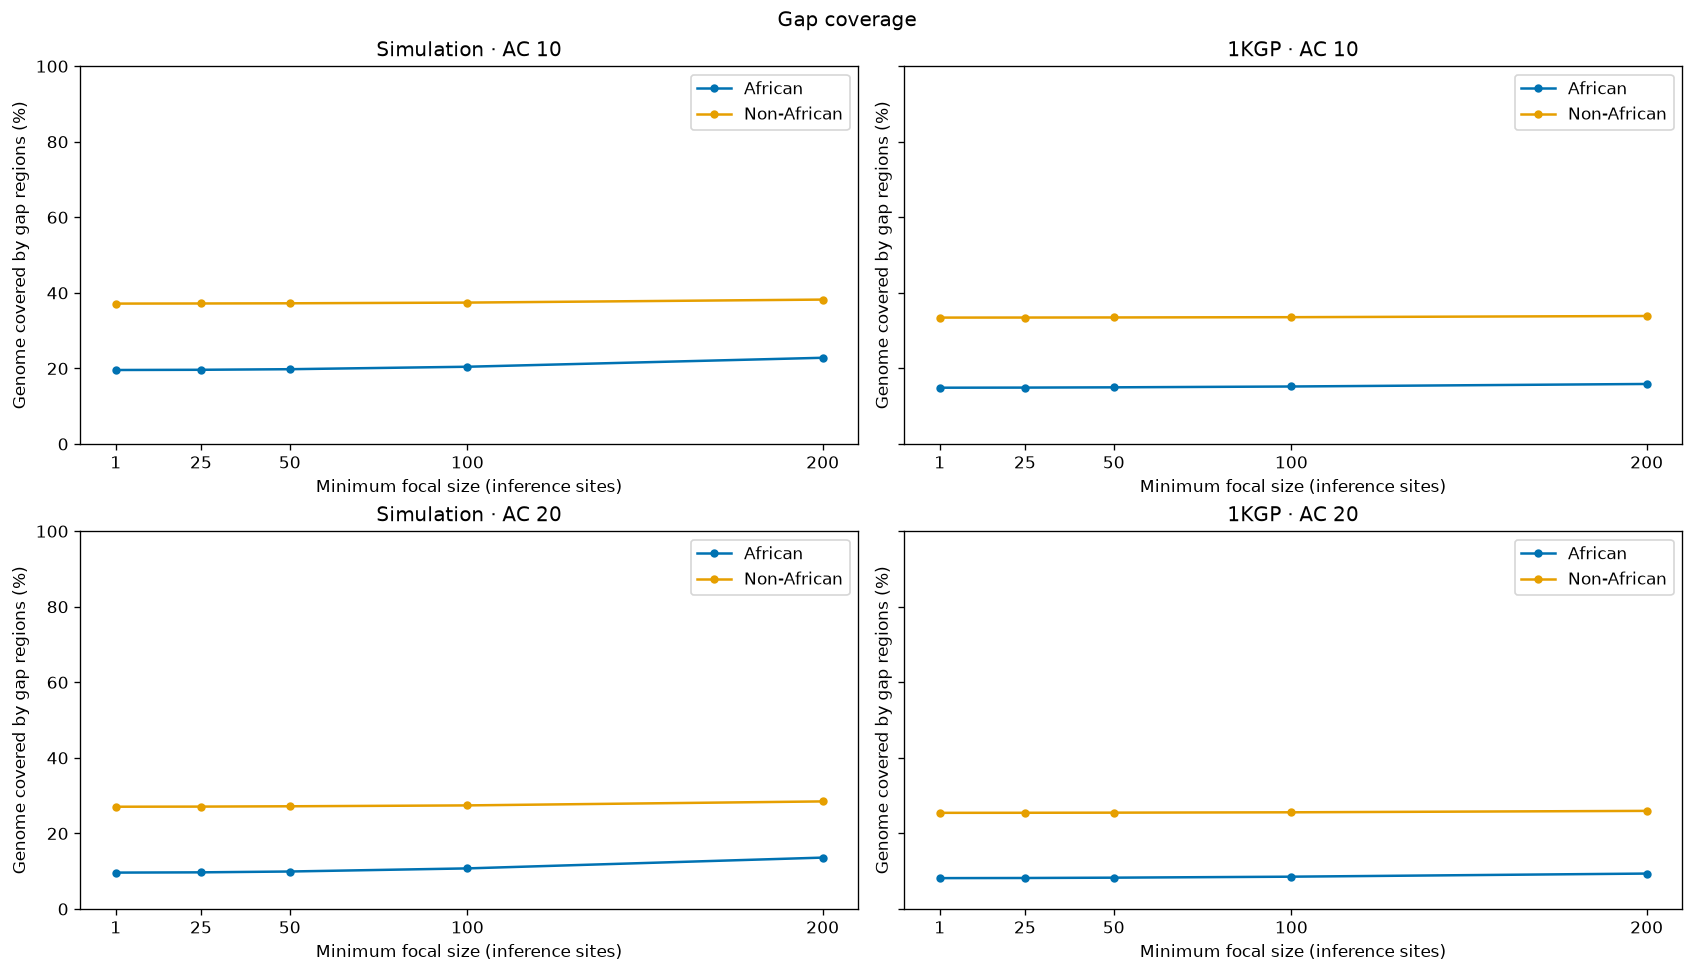

In [9]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_coverage(
        "gap",
        "Gap coverage",
        curve_values=ac_cutoffs,
        comparisons=comparisons,
        config=config,
        x_values=minimum_sizes,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        plot_population_colors={"African": "#0072B2", "Non-African": "#E69F00"},
        x_parameter="min_focal_region_size",
        curve_parameter="ac_cutoff",
        x_label="Minimum focal size (inference sites)",
        curve_label="AC {value}",
        x_value_label="Min {value}",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(fig, "gap_coverage", output_dir=output_dir)

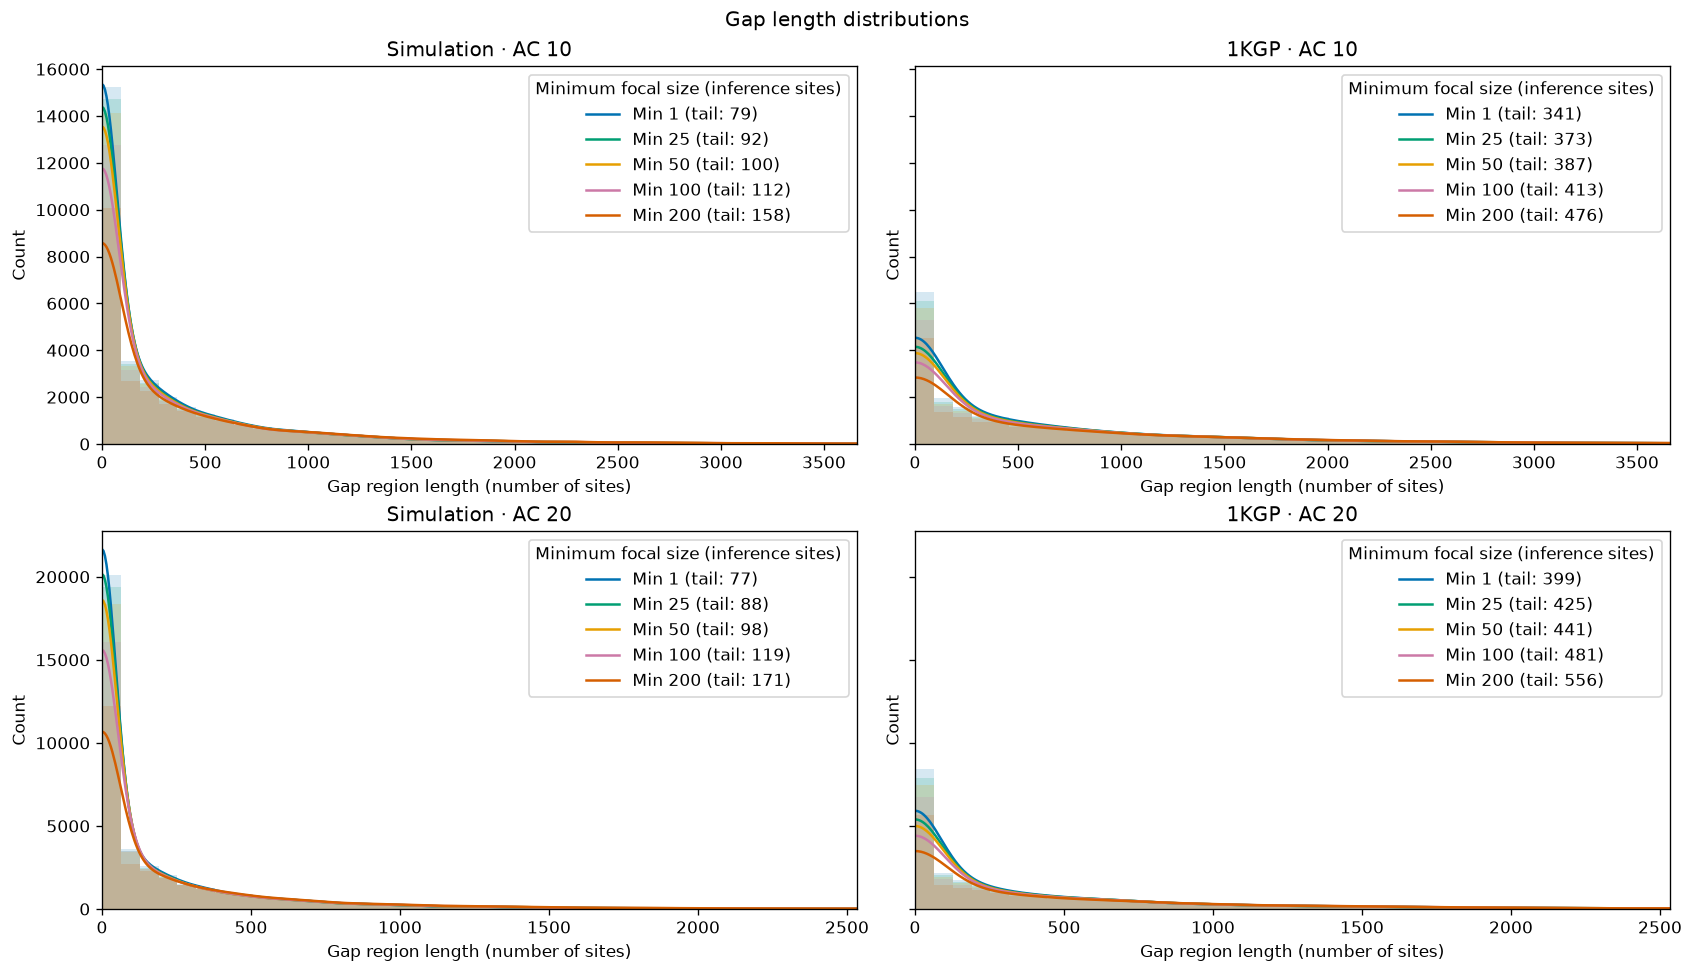

In [10]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_length_distribution(
        "gap",
        "Gap length distributions",
        curve_values=ac_cutoffs,
        config=config,
        lengths=lengths,
        x_colors=minimum_colors,
        x_values=minimum_sizes,
        plot_histogram_alpha=0.16,
        plot_histogram_bins=40,
        plot_kde_bandwidth="scott",
        plot_kde_grid_size=512,
        plot_length_display_quantile=0.99,
        plot_line_width=1.5,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="min_focal_region_size",
        curve_parameter="ac_cutoff",
        x_label="Minimum focal size (inference sites)",
        curve_label="AC {value}",
        x_value_label="Min {value}",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(fig, "gap_length_distributions", output_dir=output_dir)

## Switch composition

Bars stack raw mean counts, from bottom to top: within focal coverage, within
gaps, and at gap seams. Switches are classified using the provenance of their
adjacent inference sites; equal parents across a seam contribute no switch.
Each Greedy bar uses its own mask. Full HMM totals are invariant across
minimum sizes, but their categories depend on the mask. The Full HMM bar uses
**the minimum-size-1 mask for the row's AC cutoff**, as set in the config.

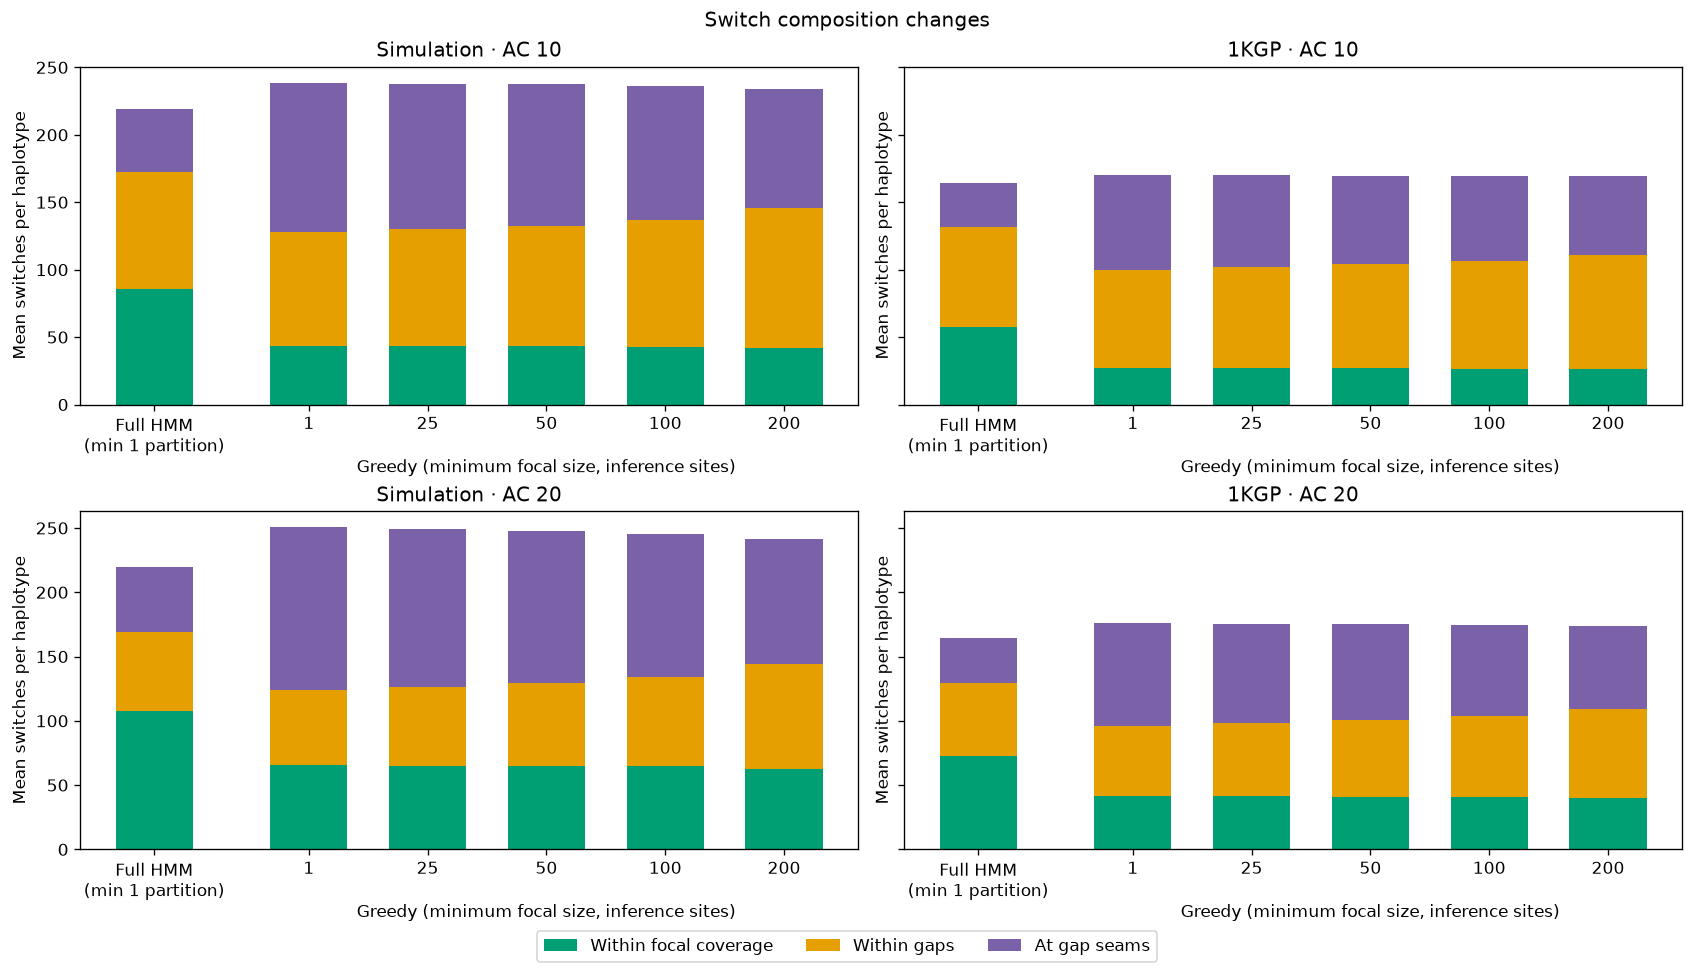

In [11]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_switch_composition(
        curve_values=ac_cutoffs,
        comparisons=comparisons,
        config=config,
        x_values=minimum_sizes,
        plot_bar_width=0.65,
        plot_full_stitched_gap_bar_widths=1,
        plot_group_label_y=-0.2,
        plot_panel_height=4,
        plot_panel_width=7,
        plot_switch_categories=["focal", "gap", "seam"],
        plot_switch_colors=["#009E73", "#E69F00", "#7B61A8"],
        plot_switch_labels=["Within focal coverage", "Within gaps", "At gap seams"],
        x_parameter="min_focal_region_size",
        curve_parameter="ac_cutoff",
        x_label="Minimum focal size (inference sites)",
        curve_label="AC {value}",
        x_value_label="Min {value}",
        baseline_partition=1,
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(fig, "switch_composition_changes", output_dir=output_dir)

## Parent agreement

Agreement compares original reference parent IDs at inference sites, using
only sites within the named region as denominator. Percentages are averaged
across haplotypes, pooling populations; empty regions are excluded and counted
in the run summary. Hourglasses use the same mean ± SEM helper as switch plots.

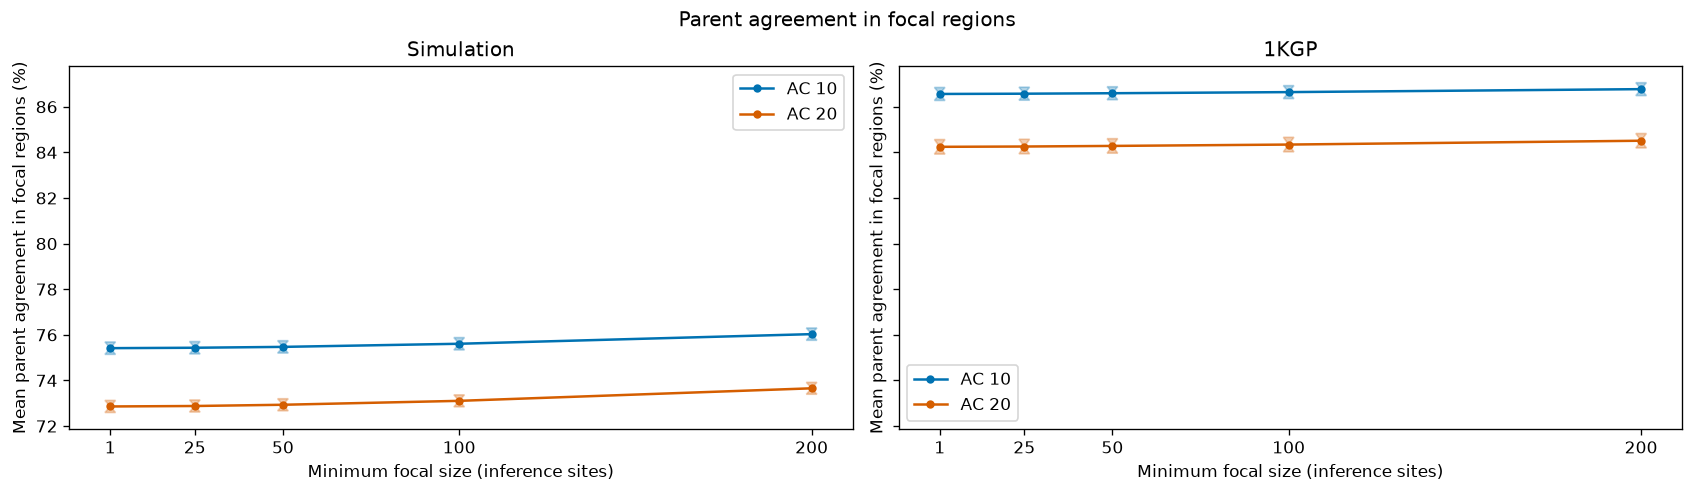

In [12]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_metric(
        "focal_agreement_percentage",
        "Parent agreement in focal regions",
        "Mean parent agreement in focal regions (%)",
        curve_values=ac_cutoffs,
        comparisons=comparisons,
        config=config,
        curve_colors=cutoff_colors,
        x_values=minimum_sizes,
        plot_hourglass_alpha=0.3,
        plot_hourglass_width=1.5,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="min_focal_region_size",
        curve_parameter="ac_cutoff",
        x_label="Minimum focal size (inference sites)",
        curve_label="AC {value}",
        x_value_label="Min {value}",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(fig, "parent_agreement_in_focal_regions", output_dir=output_dir)

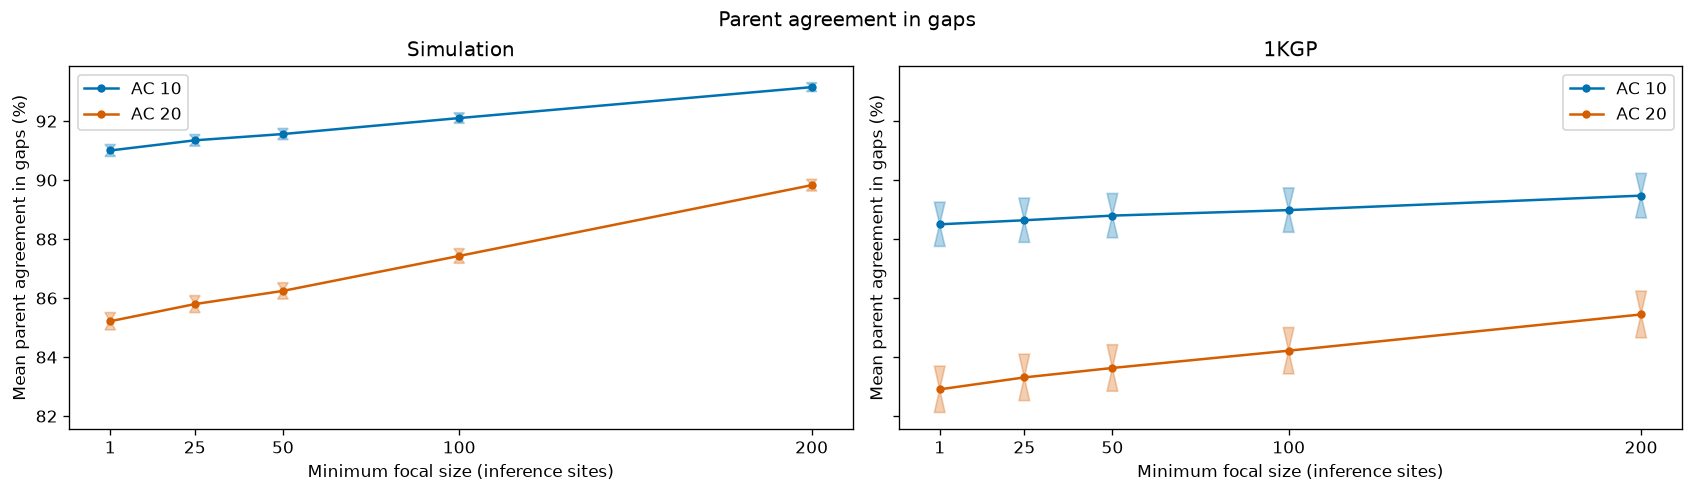

In [13]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_metric(
        "gap_agreement_percentage",
        "Parent agreement in gaps",
        "Mean parent agreement in gaps (%)",
        curve_values=ac_cutoffs,
        comparisons=comparisons,
        config=config,
        curve_colors=cutoff_colors,
        x_values=minimum_sizes,
        plot_hourglass_alpha=0.3,
        plot_hourglass_width=1.5,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="min_focal_region_size",
        curve_parameter="ac_cutoff",
        x_label="Minimum focal size (inference sites)",
        curve_label="AC {value}",
        x_value_label="Min {value}",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(fig, "parent_agreement_in_gaps", output_dir=output_dir)

## Tree sequence comparisons

Load both Full HMM outputs and every stitched matched
output in the current parameter grid. Edge and tree counts describe the
**raw saved tree sequences**, including their reference ancestry and retained
chromosome coordinates. Plot Greedy minus Full HMM counts against minimum
focal size: edge differences in the first row and tree differences in the second.
Simulation is on the left and 1KGP on the right; colour identifies AC cutoff. Negative values mean stitching produces fewer edges or trees.

In [14]:
if __name__ == "__main__":
    tree_sequences = nb_utils.min_sizes_load_tree_sequences(config_path)
    ts_statistics = tree_sequences.statistics
    ts_differences = nb_utils.tree_statistic_differences(ts_statistics)
    ts_statistics.to_csv(output_dir / "ts_statistics.csv", index=False)
    ts_differences.to_csv(output_dir / "ts_statistic_differences.csv", index=False)
    ipython_display.display(ts_differences)

,dataset,method,ac_cutoff,max_mismatches,min_focal_region_size,num_edges,num_trees,num_edges_full,num_trees_full,num_edges_difference,num_trees_difference
1,sim_n300_10mbp_error,stitched,10.0,0.0,1.0,605740,52597,594161,52861,11579,-264
2,sim_n300_10mbp_error,stitched,10.0,0.0,25.0,605338,52676,594161,52861,11177,-185
3,sim_n300_10mbp_error,stitched,10.0,0.0,50.0,604989,52721,594161,52861,10828,-140
4,sim_n300_10mbp_error,stitched,10.0,0.0,100.0,604195,52758,594161,52861,10034,-103
5,sim_n300_10mbp_error,stitched,10.0,0.0,200.0,602743,52833,594161,52861,8582,-28
6,sim_n300_10mbp_error,stitched,20.0,0.0,1.0,612785,52972,594161,52861,18624,111
7,sim_n300_10mbp_error,stitched,20.0,0.0,25.0,612071,53015,594161,52861,17910,154
8,sim_n300_10mbp_error,stitched,20.0,0.0,50.0,611297,53023,594161,52861,17136,162
9,sim_n300_10mbp_error,stitched,20.0,0.0,100.0,609899,53025,594161,52861,15738,164
10,sim_n300_10mbp_error,stitched,20.0,0.0,200.0,607457,53046,594161,52861,13296,185


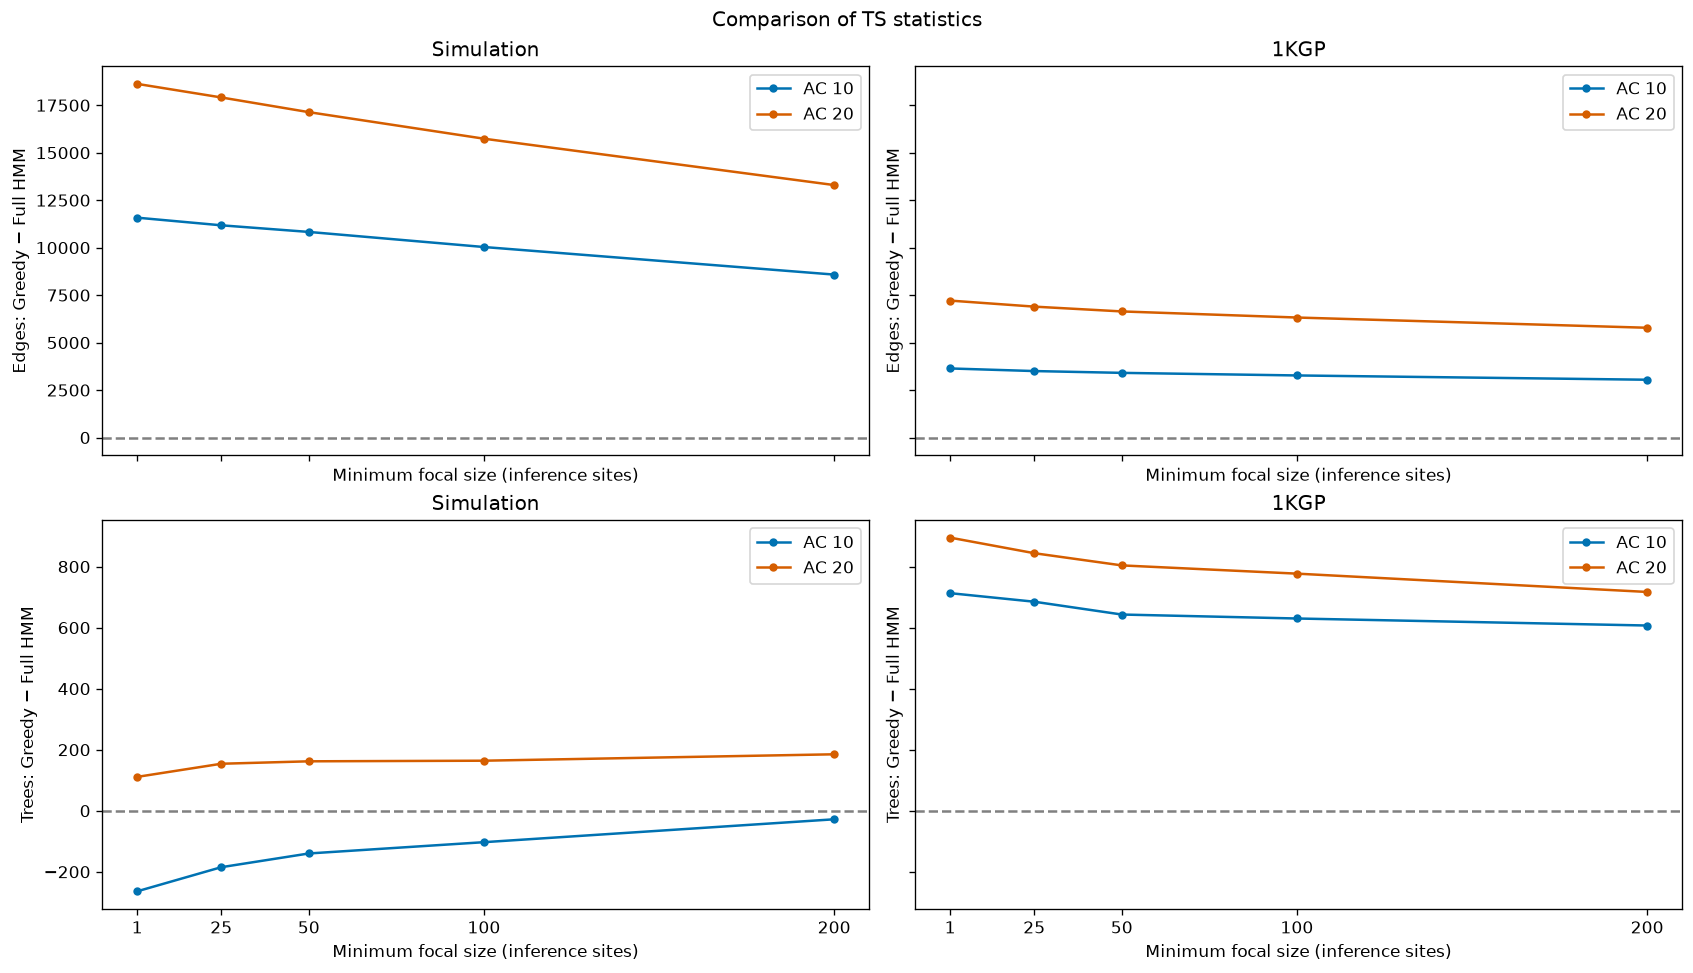

In [15]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_statistic_differences(
        curve_values=ac_cutoffs,
        config=config,
        curve_colors=cutoff_colors,
        x_values=minimum_sizes,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        ts_differences=ts_differences,
        x_parameter="min_focal_region_size",
        curve_parameter="ac_cutoff",
        x_label="Minimum focal size (inference sites)",
        curve_label="AC {value}",
        x_value_label="Min {value}",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(fig, "comparison_of_ts_statistics", output_dir=output_dir)

### Comparing ARG metrics

Compare each stitched output with its dataset's Full HMM output using
[tscompare.haplotype_arf](https://tskit.dev/tscompare/docs/stable/api.html#tscompare.haplotype_arf).
The stitched sequence is the first argument and Full HMM is the second:
ARF is the fraction of stitched node span unsupported by Full HMM (lower is
better); TPR is the fraction of Full HMM node span represented by stitching
(higher is better). Rows show ARF and TPR; columns show simulation and
1KGP. Colour identifies AC cutoff, with two lines in every panel.

Haplotypes are aligned by `(sample_id, ploidy_index)` in matched-node metadata.
Both sequences are restricted to the dataset's 10 Mb window,
translated to shared coordinates and simplified in the same sample
order, retaining unary ancestors for node-span comparisons.
Missing terminal ancestry is retained within the explicit window.

ARF and TPR retain the same definitions and sample alignment as pt3.

In [16]:
if __name__ == "__main__":
    arg_comparisons = nb_utils.min_sizes_arg_metrics(
        tree_sequences, config["datasets"], workers=config["workers"]
    )
    arg_comparisons.to_csv(output_dir / "arg_metrics.csv", index=False)
    ipython_display.display(arg_comparisons)

,dataset,ac_cutoff,max_mismatches,arf,tpr,comparison_method,reference_method,comparison_time_units,reference_time_units,min_focal_region_size
0,sim_n300_10mbp_error,10,0,0.188662,0.770524,stitched_greedy,full_hmm,unknown,unknown,1
1,sim_n300_10mbp_error,10,0,0.187798,0.771709,stitched_greedy,full_hmm,unknown,unknown,25
2,sim_n300_10mbp_error,10,0,0.186913,0.772769,stitched_greedy,full_hmm,unknown,unknown,50
3,sim_n300_10mbp_error,10,0,0.184559,0.775755,stitched_greedy,full_hmm,unknown,unknown,100
4,sim_n300_10mbp_error,10,0,0.177776,0.784276,stitched_greedy,full_hmm,unknown,unknown,200
5,sim_n300_10mbp_error,20,0,0.201861,0.746487,stitched_greedy,full_hmm,unknown,unknown,1
6,sim_n300_10mbp_error,20,0,0.201088,0.747539,stitched_greedy,full_hmm,unknown,unknown,25
7,sim_n300_10mbp_error,20,0,0.200230,0.748783,stitched_greedy,full_hmm,unknown,unknown,50
8,sim_n300_10mbp_error,20,0,0.197709,0.752160,stitched_greedy,full_hmm,unknown,unknown,100
9,sim_n300_10mbp_error,20,0,0.190676,0.761871,stitched_greedy,full_hmm,unknown,unknown,200


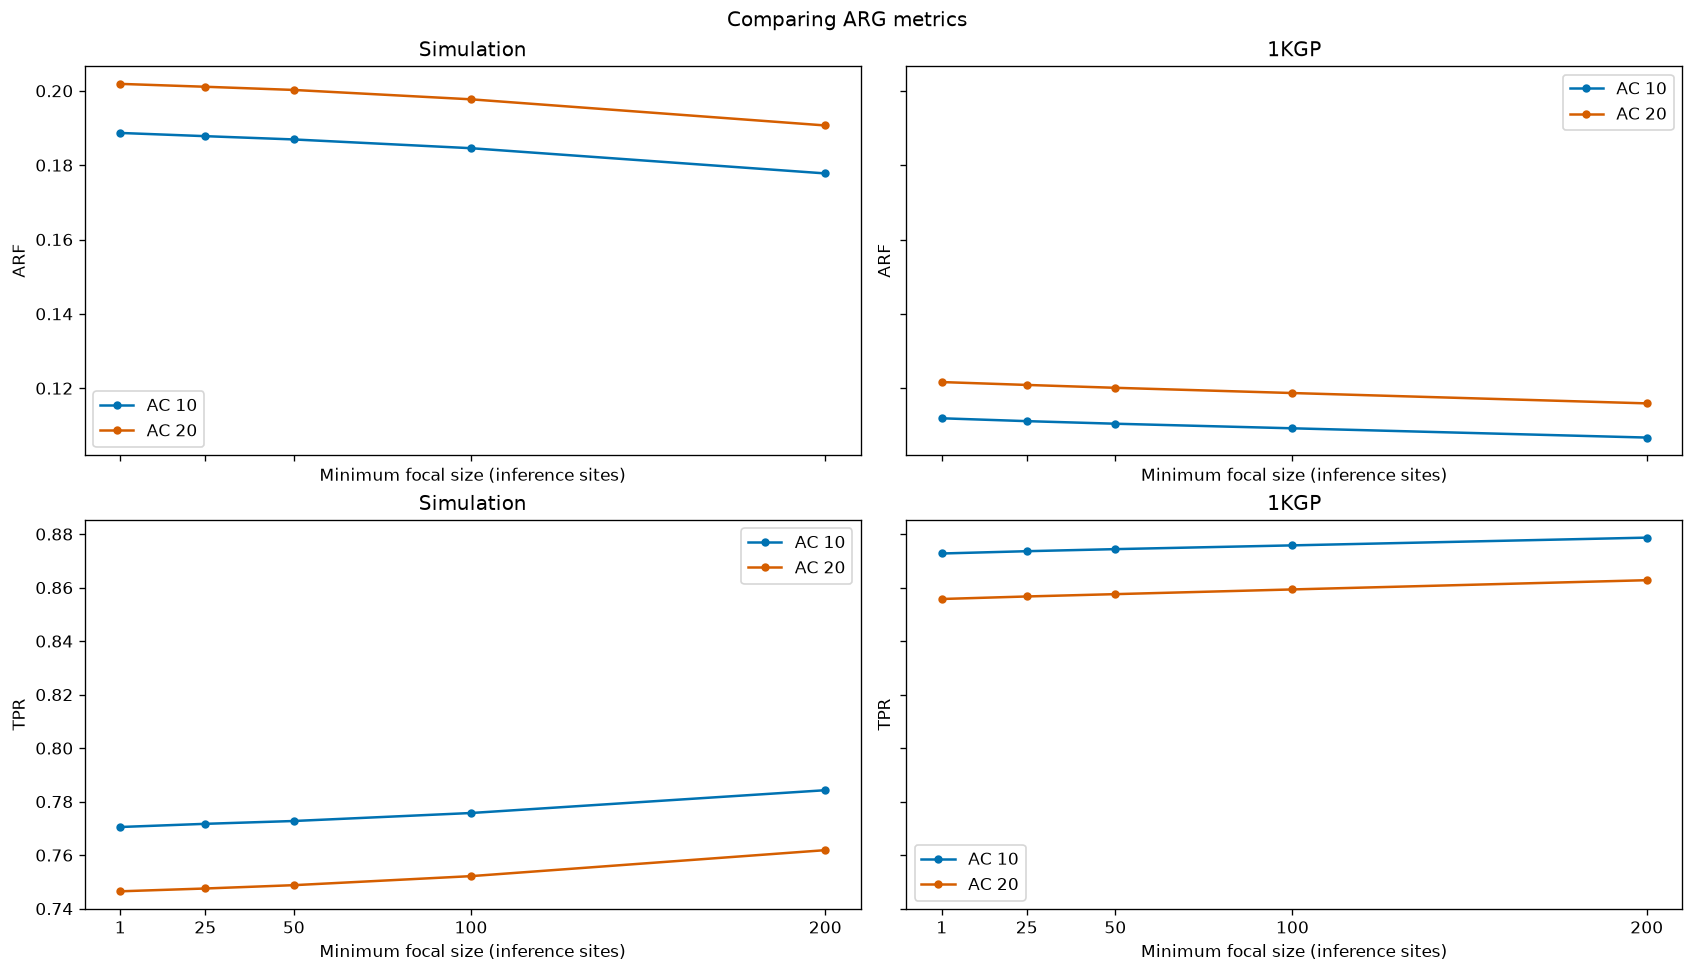

In [17]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_arg_metrics(
        curve_values=ac_cutoffs,
        arg_comparisons=arg_comparisons,
        config=config,
        curve_colors=cutoff_colors,
        x_values=minimum_sizes,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="min_focal_region_size",
        curve_parameter="ac_cutoff",
        x_label="Minimum focal size (inference sites)",
        curve_label="AC {value}",
        x_value_label="Min {value}",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(fig, "comparing_arg_metrics", output_dir=output_dir)

## ARG metrics against the true simulated tree sequence

Compare the simulation's Full HMM and each stitched output with the true ARG.
Align truth's VCF haplotype identities to the matched-node metadata and use
the same 0–10 Mb window, retaining unary ancestors. The columns show ARF and
TPR; colour identifies AC cutoff. The Full HMM baseline occupies a separate
first category and has no actual minimum size or AC cutoff. This plot uses
equally spaced categories so the baseline and minimum size 1 remain distinct.

Here ARF is the proportion of the matched output's node span not represented
in truth; TPR is the proportion of true node span represented in that output.
Lower ARF and higher TPR indicate greater agreement with the true ARG.
Each y-axis zooms to the observed values to make small differences visible.

In [18]:
if __name__ == "__main__":
    truth_comparisons = nb_utils.min_sizes_truth_arg_metrics(
        tree_sequences, config_path, workers=config["workers"]
    )
    truth_comparisons.to_csv(output_dir / "arg_metrics_against_truth.csv", index=False)
    ipython_display.display(truth_comparisons)

,dataset,ac_cutoff,max_mismatches,arf,tpr,comparison_method,reference_method,comparison_time_units,reference_time_units,min_focal_region_size
0,sim_n300_10mbp_error,NaN,NaN,0.373512,0.532529,full_hmm,true_arg,unknown,generations,NaN
1,sim_n300_10mbp_error,10.0,0.0,0.366020,0.537531,stitched_greedy,true_arg,unknown,generations,1.0
2,sim_n300_10mbp_error,10.0,0.0,0.366063,0.537575,stitched_greedy,true_arg,unknown,generations,25.0
3,sim_n300_10mbp_error,10.0,0.0,0.366078,0.537581,stitched_greedy,true_arg,unknown,generations,50.0
4,sim_n300_10mbp_error,10.0,0.0,0.366230,0.537560,stitched_greedy,true_arg,unknown,generations,100.0
5,sim_n300_10mbp_error,10.0,0.0,0.366833,0.537350,stitched_greedy,true_arg,unknown,generations,200.0
6,sim_n300_10mbp_error,20.0,0.0,0.361390,0.536316,stitched_greedy,true_arg,unknown,generations,1.0
7,sim_n300_10mbp_error,20.0,0.0,0.361473,0.536345,stitched_greedy,true_arg,unknown,generations,25.0
8,sim_n300_10mbp_error,20.0,0.0,0.361554,0.536357,stitched_greedy,true_arg,unknown,generations,50.0
9,sim_n300_10mbp_error,20.0,0.0,0.361854,0.536304,stitched_greedy,true_arg,unknown,generations,100.0


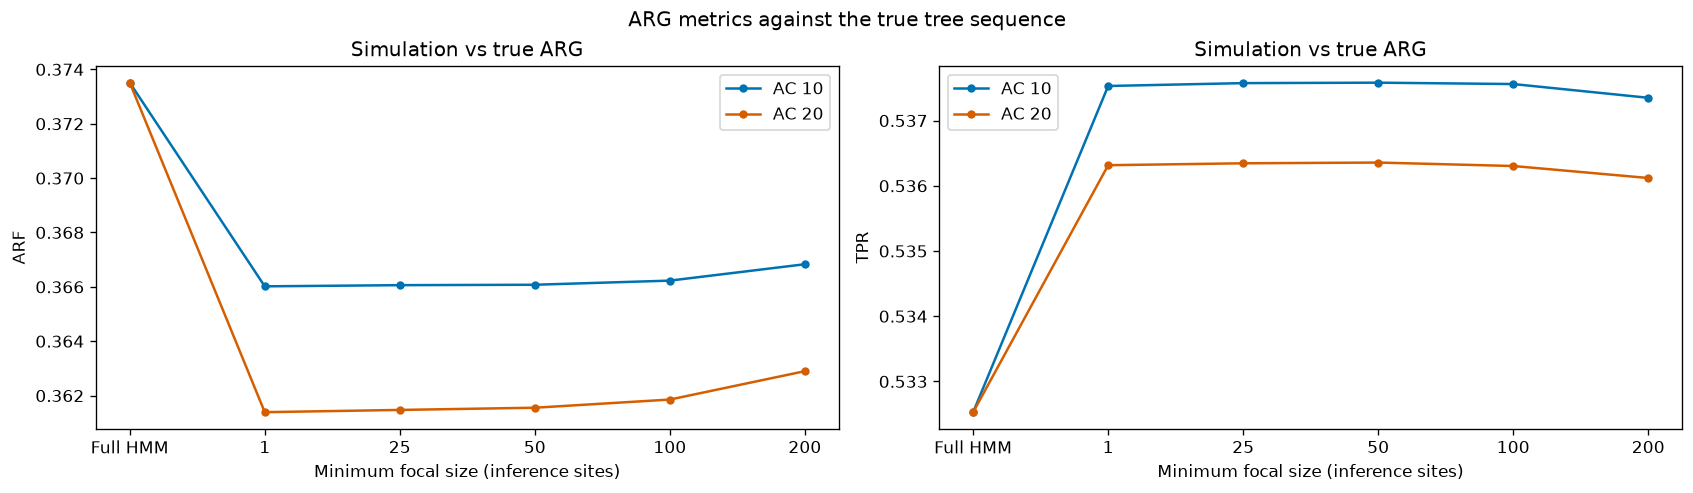

In [19]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_truth_arg_metrics(
        curve_values=ac_cutoffs,
        curve_colors=cutoff_colors,
        x_values=minimum_sizes,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        truth_comparisons=truth_comparisons,
        x_parameter="min_focal_region_size",
        curve_parameter="ac_cutoff",
        x_label="Minimum focal size (inference sites)",
        curve_label="AC {value}",
        x_value_label="Min {value}",
        baseline_x=1,
        stitched_method="stitched_greedy",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(fig, "arg_metrics_against_truth", output_dir=output_dir)

## Mutation-age correlations after dating

All 22 inferred ARGs (Full HMM and ten Greedy cases for each dataset) are
post-processed with the updated local tsinfer. Singleton and other omitted
sites are restored from the observed sample VCZ, retaining the inferred
topology and observed alleles. The analysed window is retained, then
`tsdate.preprocess_ts` splits disjoint nodes before `tsdate.date` uses the
variational-gamma method. Dated ARGs and input/settings manifests are saved
under `dated_args`; unchanged results are reused on subsequent runs.

Mutation rates are 2.35 × 10⁻⁸ per bp per generation for the simulation
(from its mutation provenance), and a configured 1.29 × 10⁻⁸ for 1KGP.
Singletons retain their observed phase. See the
[tsdate dating and preprocessing documentation](https://tskit.dev/tsdate/docs/stable/usage.html).

**These plots compare mutation ages, not node ages.** Inferred ages are
tsdate's posterior mutation means (`mutation.metadata['mn']`), rather than
branch-midpoint times in the mutation table. Truth uses the simulated
mutation event times. Mutations are paired by genomic position and identical
ancestral/derived states. Sites with zero or multiple mutations, or nonfinite
ages, are excluded. Each panel/dataset uses one common set across all its
cases, so the plotted correlations are directly comparable. The CSV reports
the number of matched mutations. Correlations are unweighted Pearson r on
ages in generations, conditional on this common unambiguous mutation set.

Left: simulation Full HMM and all Greedy cases against true mutation ages.
Right: Greedy against the dated Full HMM, with colour for AC cutoff and line
style for dataset. The left panel uses a separate Full HMM category; the right
panel uses numerical minimum sizes.

In [4]:
if __name__ == "__main__":
    dated_runs = nb_utils.dating_date_all(config_path)
    dated_runs.to_csv(output_dir / "dated_arg_summary.csv", index=False)
    mutation_age_results = nb_utils.dating_mutation_correlations(
        dated_runs, config_path
    )
    mutation_age_results.to_csv(
        output_dir / "mutation_age_correlations.csv", index=False
    )
    ipython_display.display(
        mutation_age_results.loc[mutation_age_results.frequency_bin.eq("all")]
    )

,dataset,comparison_method,ac_cutoff,min_focal_region_size,max_mismatches,reference_method,frequency_bin,matched_mutations,pearson_r,mean_estimated_age,mean_reference_age,mean_error_generations,median_absolute_error_generations
0,sim_n300_10mbp_error,stitched_greedy,10.0,1.0,0.0,full_hmm,all,94650,0.871807,4926.056297,4665.118249,260.938048,59.055913
1,sim_n300_10mbp_error,stitched_greedy,10.0,25.0,0.0,full_hmm,all,94650,0.876604,4925.963121,4665.118249,260.844872,58.686587
2,sim_n300_10mbp_error,stitched_greedy,10.0,50.0,0.0,full_hmm,all,94650,0.881127,4914.567215,4665.118249,249.448966,58.084060
3,sim_n300_10mbp_error,stitched_greedy,10.0,100.0,0.0,full_hmm,all,94650,0.887441,4894.588930,4665.118249,229.470681,56.829365
4,sim_n300_10mbp_error,stitched_greedy,10.0,200.0,0.0,full_hmm,all,94650,0.896480,4870.230395,4665.118249,205.112146,54.018080
5,sim_n300_10mbp_error,stitched_greedy,20.0,1.0,0.0,full_hmm,all,94650,0.871808,4929.486546,4665.118249,264.368297,75.153729
6,sim_n300_10mbp_error,stitched_greedy,20.0,25.0,0.0,full_hmm,all,94650,0.876545,4928.463036,4665.118249,263.344787,74.513972
7,sim_n300_10mbp_error,stitched_greedy,20.0,50.0,0.0,full_hmm,all,94650,0.880201,4917.233451,4665.118249,252.115202,73.266683
8,sim_n300_10mbp_error,stitched_greedy,20.0,100.0,0.0,full_hmm,all,94650,0.887298,4891.383305,4665.118249,226.265056,71.202137
9,sim_n300_10mbp_error,stitched_greedy,20.0,200.0,0.0,full_hmm,all,94650,0.890033,4875.203734,4665.118249,210.085485,66.047107


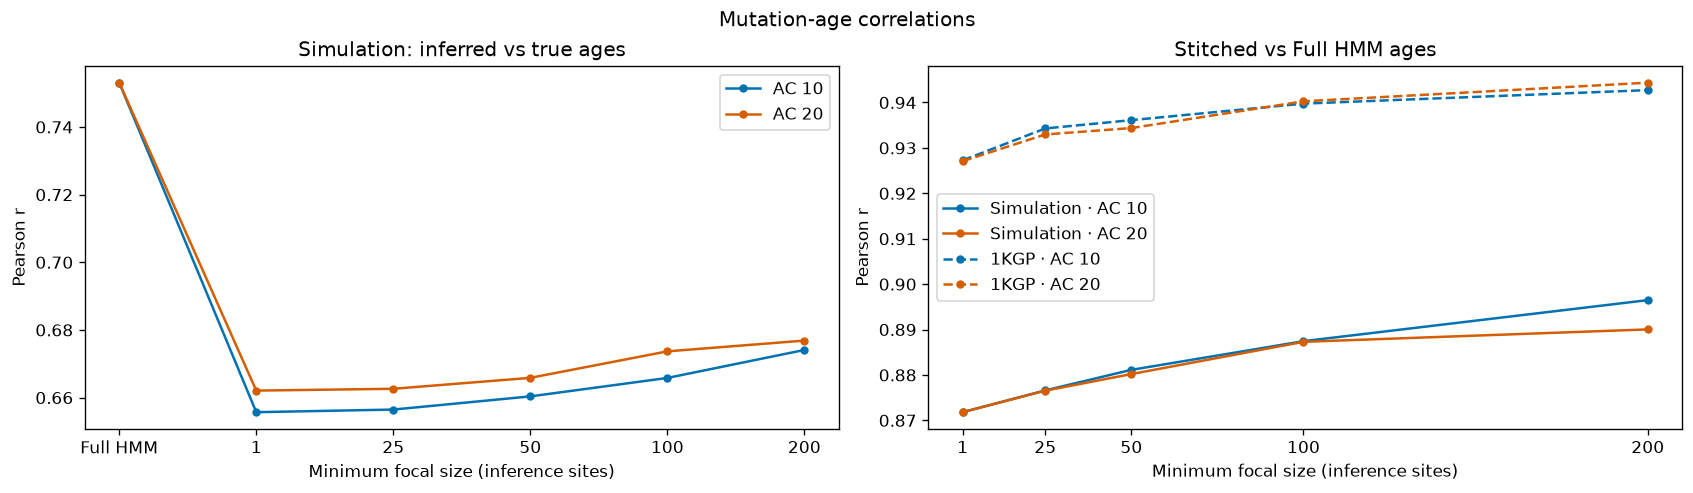

In [5]:
if __name__ == "__main__":
    fig = nb_plot.correlation_figure(
        mutation_age_results,
        config,
        experiment,
        curve_colors=["#0072B2", "#D55E00"],
        curve_label="AC {value}",
        curve_parameter="ac_cutoff",
        dataset_linestyles={"sim_n300_10mbp_error": "-", "tgp_n300_10mbp": "--"},
        line_width=1.5,
        marker_size=4,
        panel_height=4,
        panel_width=7,
        x_label="Minimum focal size (inference sites)",
        x_parameter="min_focal_region_size",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(fig, "mutation_age_correlations", output_dir=output_dir)

## Mutation-age correlations by derived allele frequency

The three rows split observed derived allele frequency (DAF) into
**DAF < 0.01**, **0.01 ≤ DAF < 0.5**, and **DAF ≥ 0.5**. Boundaries enter
the upper bin. Frequencies are measured among the 600 sample haplotypes in
the dated Full HMM, and that bin assignment is held fixed for every case in
both panels. These are derived frequencies, rather than minor frequencies.
Each row repeats the overall truth and Full HMM comparisons on that subset;
the same shared-mutation and posterior-mean rules apply. Within-bin Pearson r
can be lower simply because conditioning on frequency restricts the age range.

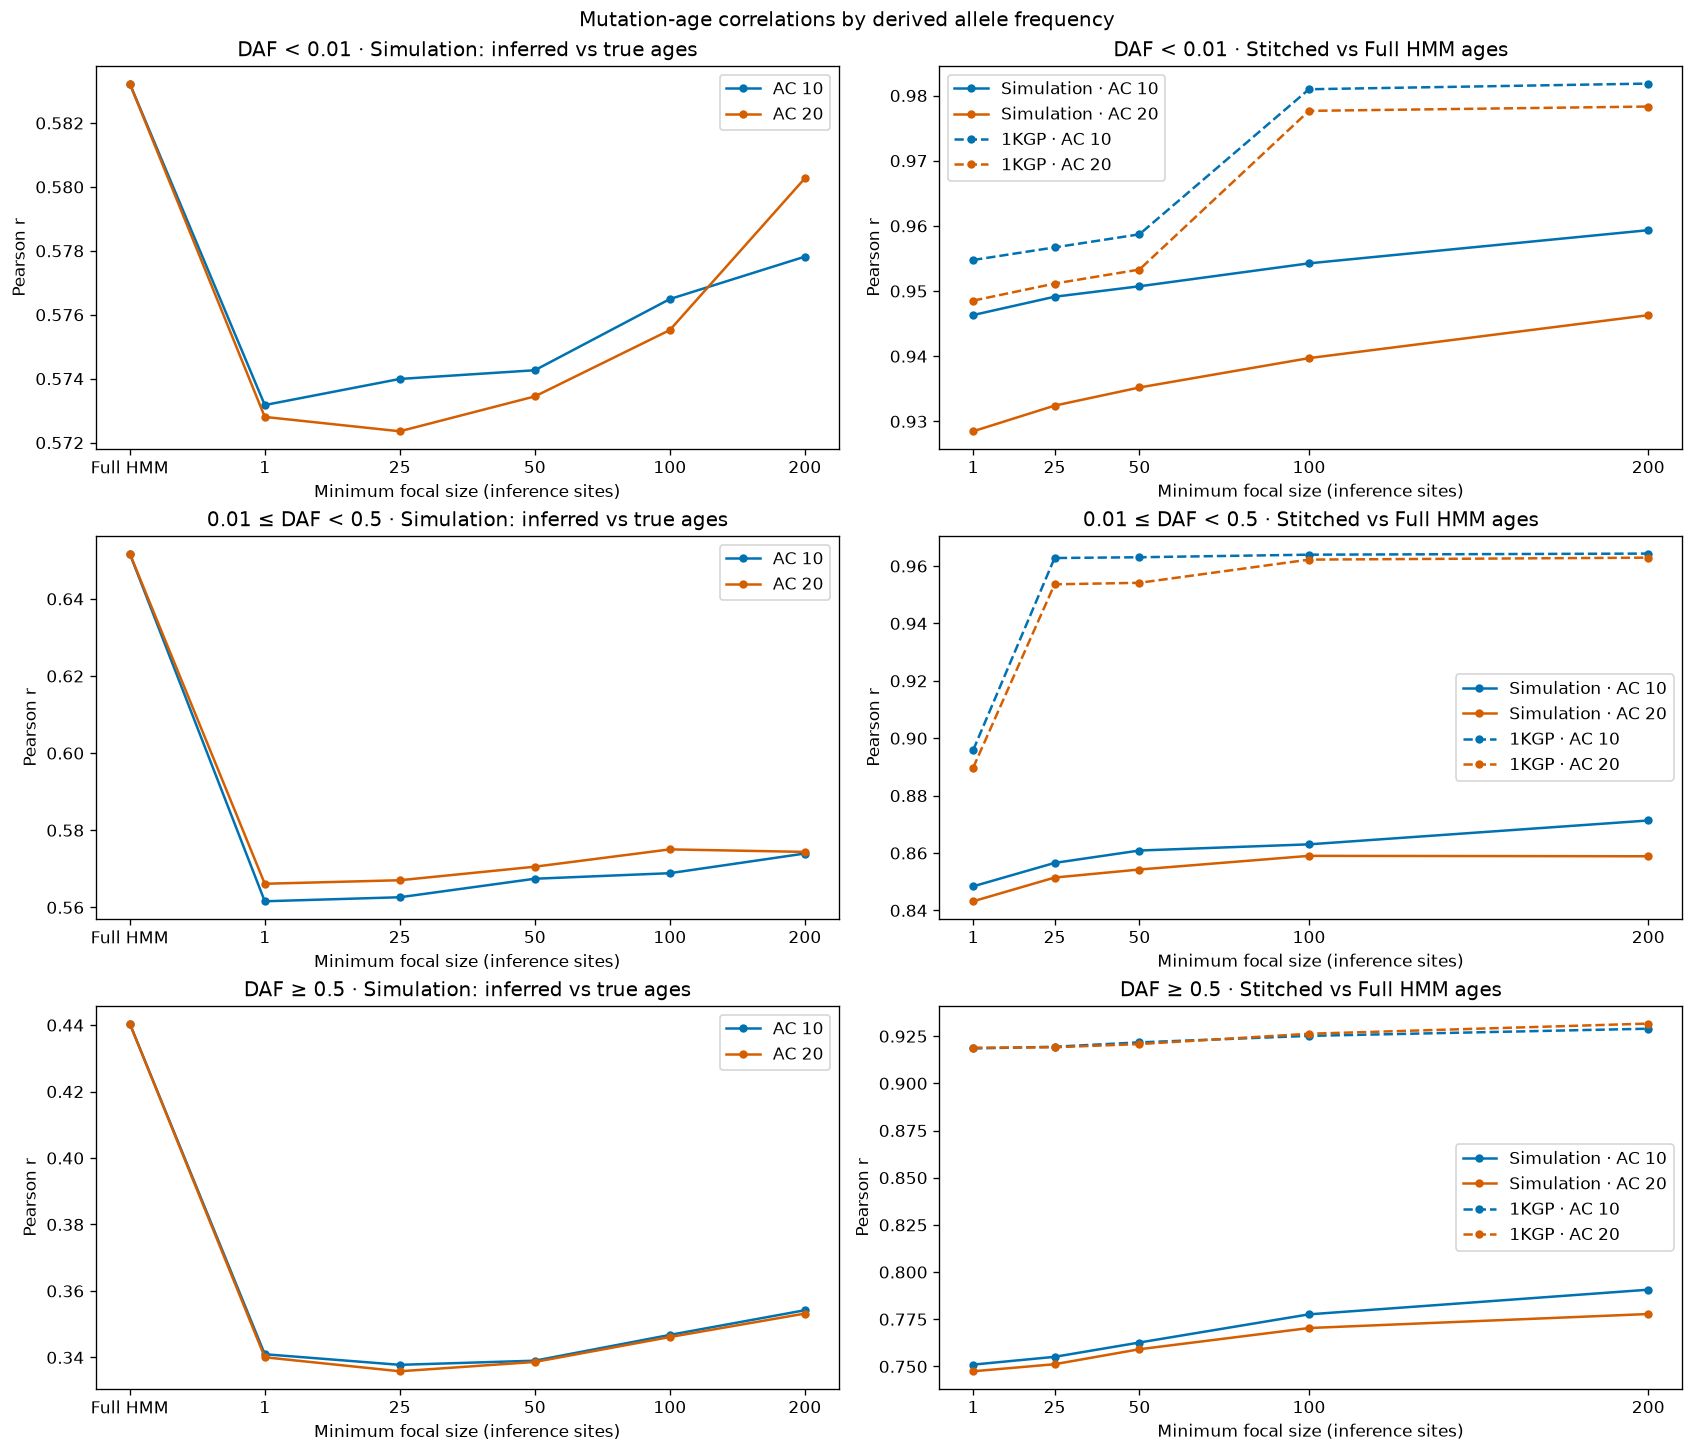

In [6]:
if __name__ == "__main__":
    fig = nb_plot.correlation_figure(
        mutation_age_results,
        config,
        experiment,
        split_frequency=True,
        curve_colors=["#0072B2", "#D55E00"],
        curve_label="AC {value}",
        curve_parameter="ac_cutoff",
        dataset_linestyles={"sim_n300_10mbp_error": "-", "tgp_n300_10mbp": "--"},
        line_width=1.5,
        marker_size=4,
        panel_height=4,
        panel_width=7,
        x_label="Minimum focal size (inference sites)",
        x_parameter="min_focal_region_size",
        dpi=120,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.save_figure(
        fig, "mutation_age_correlations_by_frequency", output_dir=output_dir
    )

## Full HMM versus stitched mutation-age densities

These density scatterplots compare **Full HMM posterior mutation ages on the
x-axis** with **stitched posterior mutation ages on the y-axis**, across
**all allele frequencies**. Simulation and 1KGP each have a separate grid.
Columns follow the parameter on the line plots' x-axis; rows follow their
coloured curves. Every panel within a dataset uses the same common mutation
set as the overall Full HMM correlation panel, with identical axes, bins and
colour scale. Ages and mutation counts both use logarithmic scales; the
dashed line marks equal ages. Annotated Pearson r uses ages in generations
before log transformation. No simulation truth or frequency filtering enters
these comparisons.

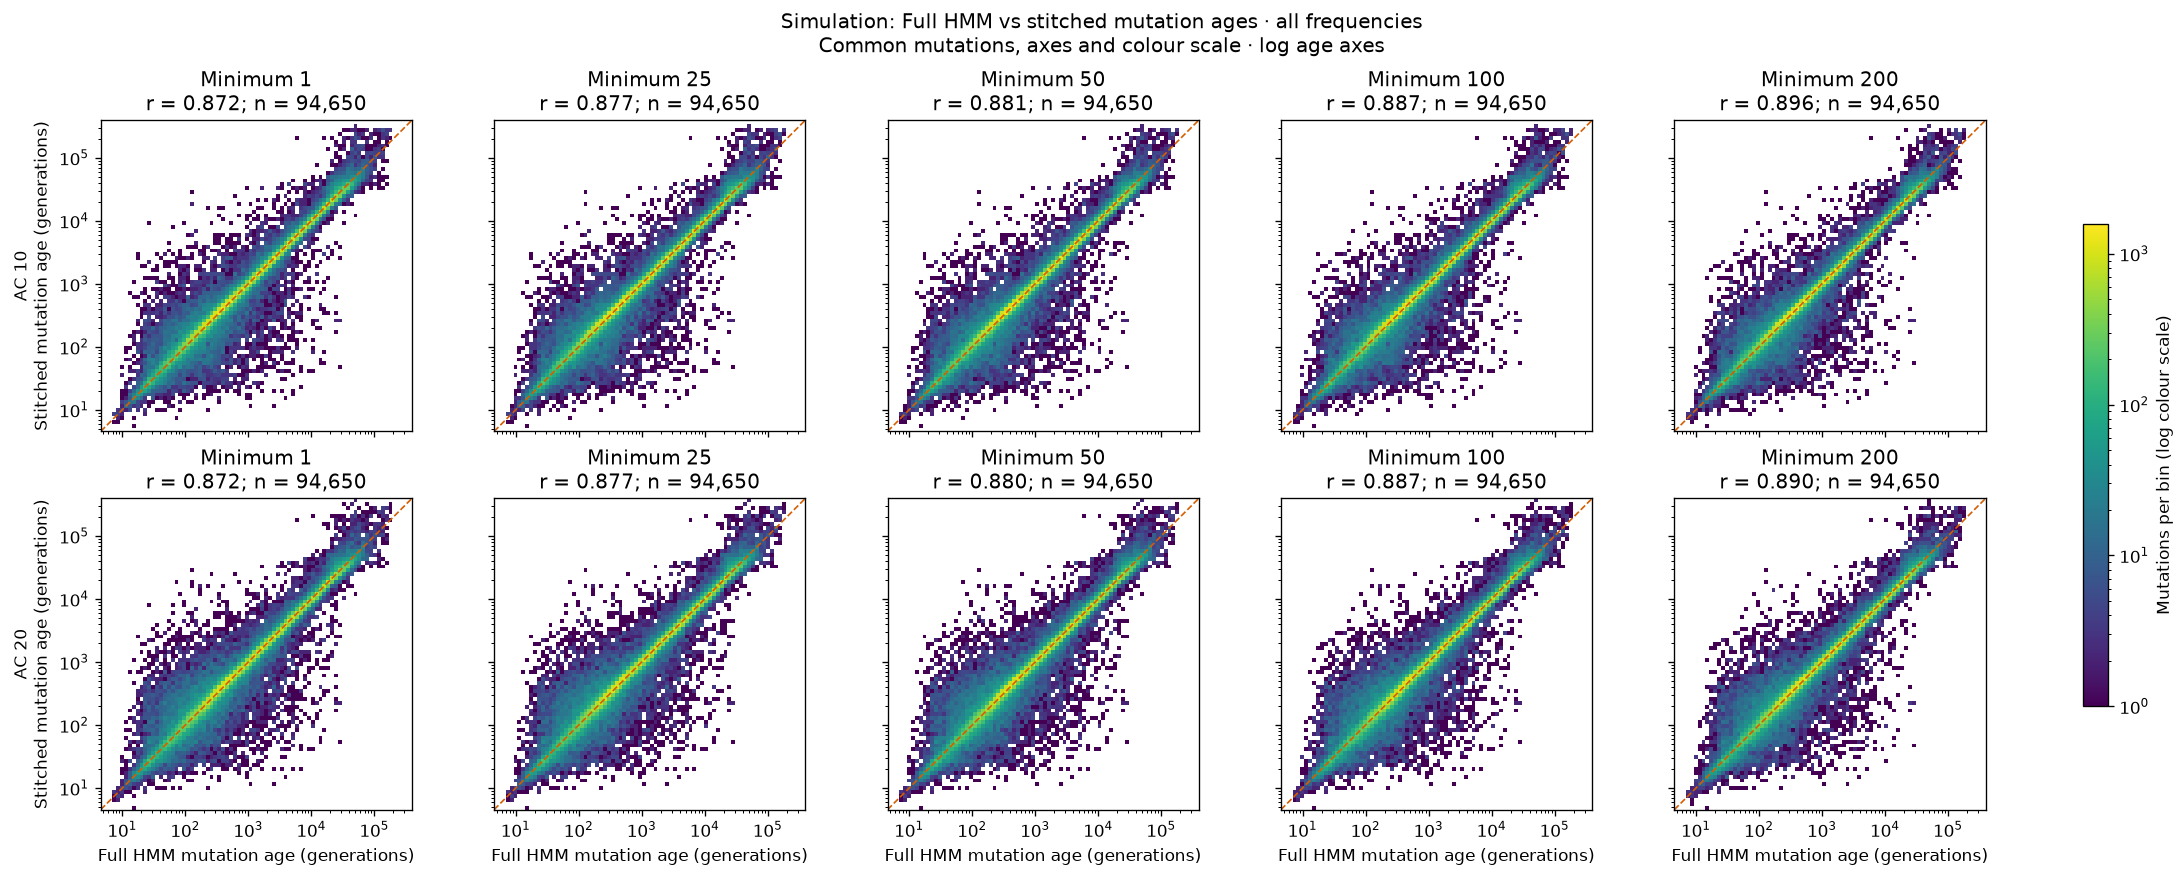

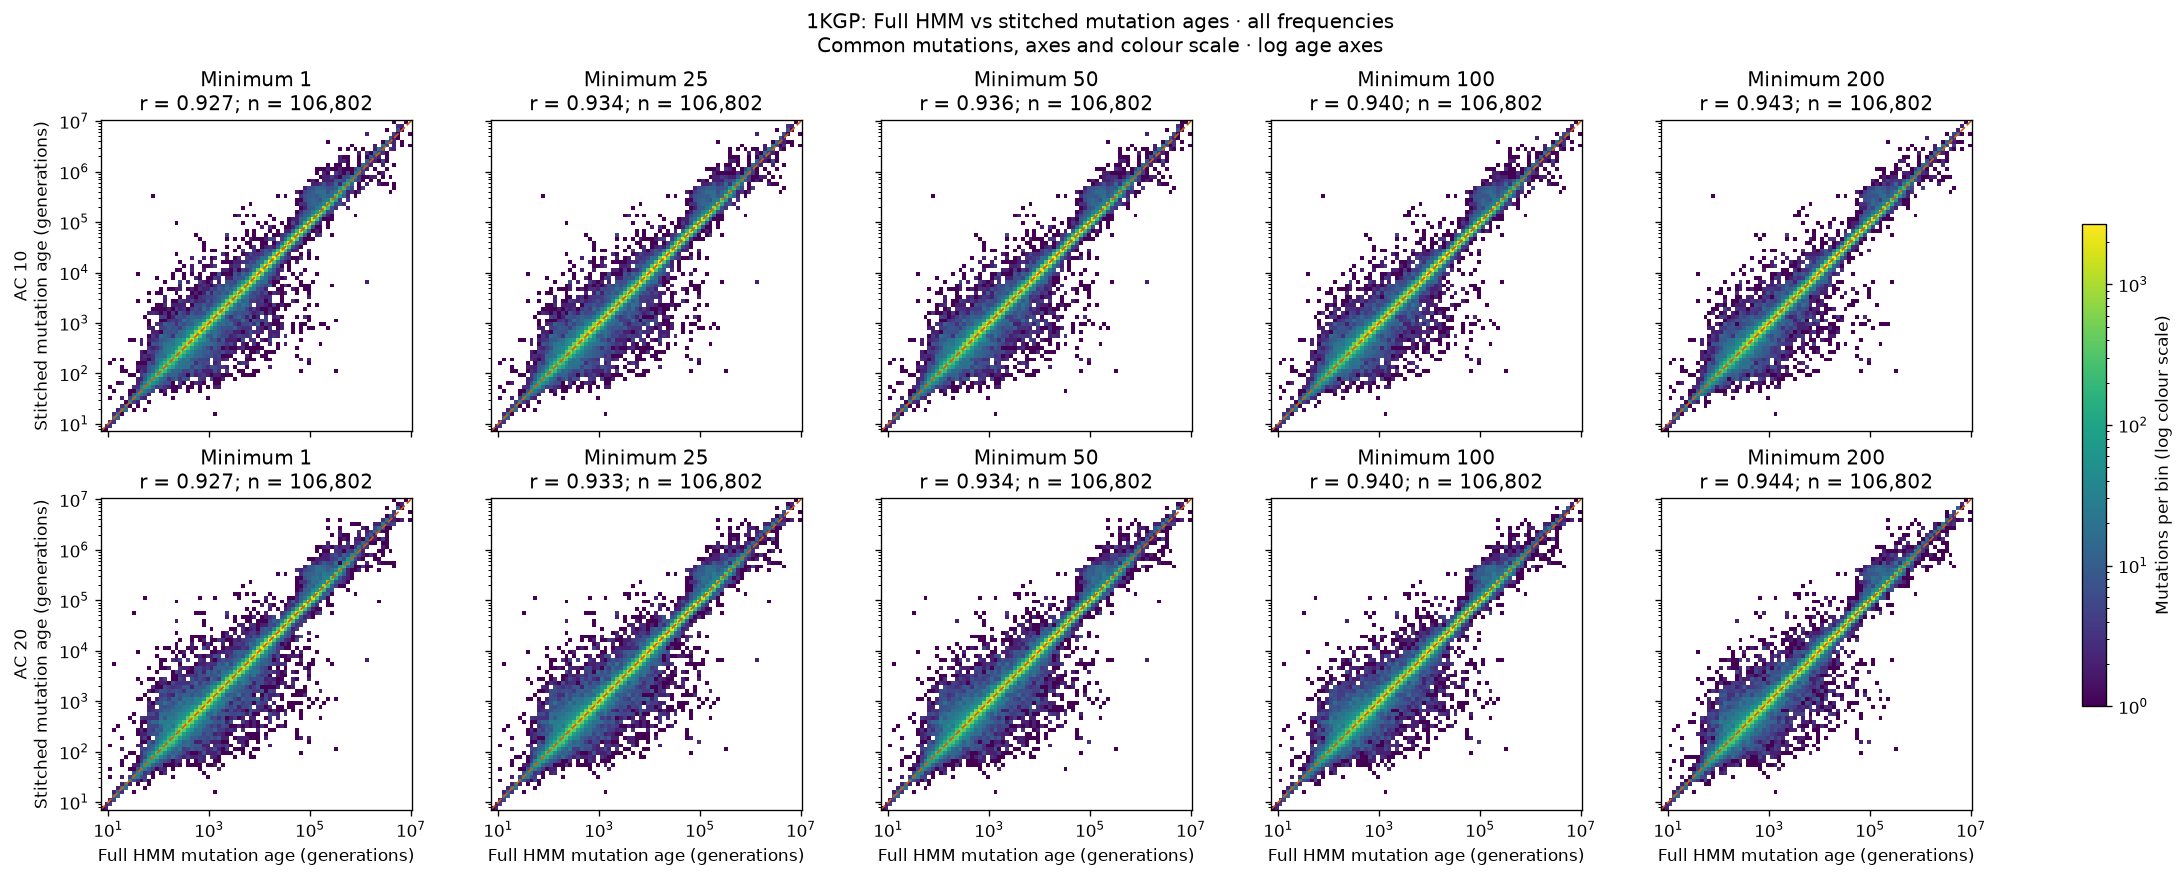

In [5]:
if __name__ == "__main__":
    stitched_age_pairs = nb_utils.stitched_mutation_age_pairs(dated_runs, config_path)
    for dataset in config["datasets"]:
        if dataset["name"] in config["dating"]["compare_full_datasets"]:
            fig = nb_plot.stitched_age_density_figure(
                stitched_age_pairs,
                config,
                experiment,
                dataset,
                age_scale="log",
                bins=80,
                cmap="viridis",
                colorbar_shrink=0.7,
                column_label="Minimum {value:g}",
                curve_label="AC {value}",
                curve_parameter="ac_cutoff",
                identity_color="#D55E00",
                panel_size=3.6,
                x_parameter="min_focal_region_size",
                dpi=120,
                show_top_spine=True,
                show_right_spine=True,
            )
            nb_plot.save_figure(
                fig, f"mutation_age_density_{dataset['name']}", output_dir=output_dir
            )